In [59]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.tree import export_text
from sklearn.tree import DecisionTreeClassifier


In [2]:
df=pd.read_csv('bank-additional-full.csv',sep=';')
client_cols = ["age", "job", "marital", "education", "default", "housing", "loan"]
campaign_cols = ["contact", "month", "day_of_week", "duration", "campaign", "pdays", "previous", "poutcome"]
macro_cols = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
target_col = "y"


In [3]:

print(df[client_cols].head())
print(df[campaign_cols].head())
print(df[macro_cols].head())
print(df[target_col].head())

   age        job  marital    education  default housing loan
0   56  housemaid  married     basic.4y       no      no   no
1   57   services  married  high.school  unknown      no   no
2   37   services  married  high.school       no     yes   no
3   40     admin.  married     basic.6y       no      no   no
4   56   services  married  high.school       no      no  yes
     contact month day_of_week  duration  campaign  pdays  previous  \
0  telephone   may         mon       261         1    999         0   
1  telephone   may         mon       149         1    999         0   
2  telephone   may         mon       226         1    999         0   
3  telephone   may         mon       151         1    999         0   
4  telephone   may         mon       307         1    999         0   

      poutcome  
0  nonexistent  
1  nonexistent  
2  nonexistent  
3  nonexistent  
4  nonexistent  
   emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
0           1.1          93.

In [4]:

print(df.shape)
print(df.info())
print(df.describe())
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True))
print(df.isnull().sum())
print(df.duplicated().sum())
print(df[df.duplicated(keep=False)])

(41188, 21)
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null

In [5]:
df_clean=df.drop_duplicates()
print(df_clean.shape)

(41176, 21)


In [6]:
print(F"Count of pdays is:{df_clean["pdays"].value_counts()[999]}")

Count of pdays is:39661


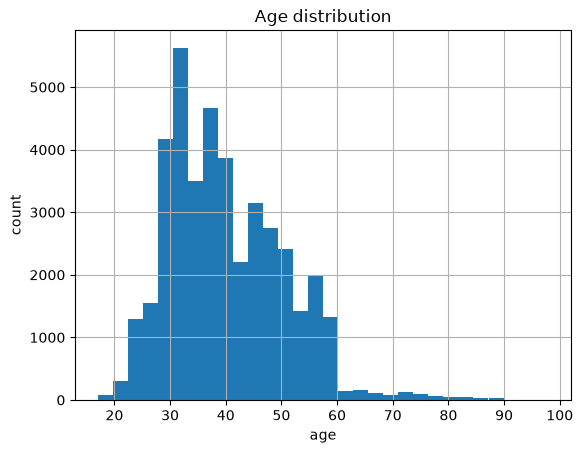

In [7]:
df["age"].hist(bins=30)
plt.title("Age distribution")
plt.xlabel("age")
plt.ylabel("count")
plt.show()

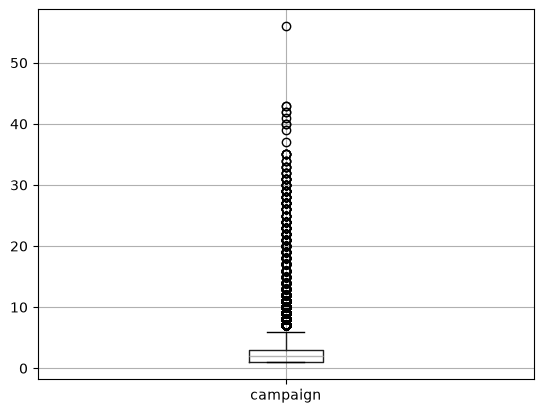

In [8]:
df.boxplot(column="campaign")
plt.show()

In [9]:
q1=df["campaign"].quantile(0.25)
q3=df["campaign"].quantile(0.75)
iqr=q3-q1
upper=q3+1.5*iqr
lower=q1-1.5*iqr
outliers=((df["campaign"]<lower) | (df["campaign"]>upper)).sum()
print(outliers)

2406


In [10]:
q1=df["age"].quantile(0.25)
q3=df["age"].quantile(0.75)
iqr=q3-q1
upper=q3+1.5*iqr
lower=q1-1.5*iqr
outliers=((df["age"]<lower) | (df["age"]>upper)).sum()
print(outliers)


469


In [11]:
df["y_num"] = df["y"].map({"no": 0, "yes": 1})

for col in ["job", "month", "poutcome"]:
    result = df.groupby(col)["y_num"].agg(["mean", "count"])
    result["mean"] = result["mean"] * 100
    print(result.sort_values("mean", ascending=False).round(1))
    print()

               mean  count
job                       
student        31.4    875
retired        25.2   1720
unemployed     14.2   1014
admin.         13.0  10422
management     11.2   2924
unknown        11.2    330
technician     10.8   6743
self-employed  10.5   1421
housemaid      10.0   1060
entrepreneur    8.5   1456
services        8.1   3969
blue-collar     6.9   9254

       mean  count
month             
mar    50.5    546
dec    48.9    182
sep    44.9    570
oct    43.9    718
apr    20.5   2632
aug    10.6   6178
jun    10.5   5318
nov    10.1   4101
jul     9.0   7174
may     6.4  13769

             mean  count
poutcome                
success      65.1   1373
failure      14.2   4252
nonexistent   8.8  35563



In [12]:
month_stats = df.groupby("month")["y_num"].agg(["mean", "count"])
print(month_stats["mean"].corr(month_stats["count"]))

-0.8109922292715084


In [13]:
print(df.groupby("y")["duration"].mean())

y
no     220.844807
yes    553.191164
Name: duration, dtype: float64


In [14]:
text_cols = df.select_dtypes(include=["object", "str"]).columns

for col in text_cols:
    print(col, (df[col] == "unknown").sum())

job 330
marital 80
education 1731
default 8597
housing 990
loan 990
contact 0
month 0
day_of_week 0
poutcome 0
y 0


In [15]:
print(round((df["pdays"] == 999).mean() * 100,2))

96.32


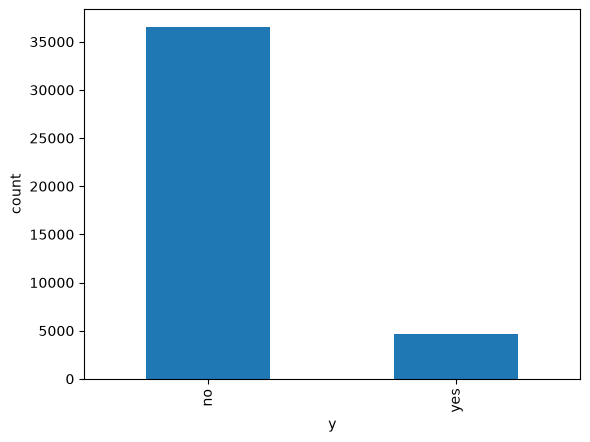

In [16]:
df["y"].value_counts().plot(kind="bar")
plt.ylabel("count")
plt.show()

Part 2





.



In [17]:
print(df_clean.isnull().sum())
print(df_clean.duplicated().sum())

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64
0


In [18]:
df_model = df.copy()
df_model["y"] = df_model["y"].map({"no": 0, "yes": 1})
df_model=df_model.drop(columns=["duration"])
df_model["previously_contacted"] = (df_model["pdays"] != 999).astype(int)
df_model.loc[df_model["pdays"] == 999, "pdays"] = 0
unknown_counts = (df_model == "unknown").sum()
X = df_model.drop(columns=["y"])
X = X.drop(columns=["y_num"])
y = df_model["y"]
print(X.shape)


(41188, 20)


Training the model












.






.
.
.
/

In [19]:
X_train,X_test,y_train,y_test=train_test_split(
    X, y , test_size=0.2 ,stratify=y, random_state=42
)
print(X_train.shape,X_test.shape)
print(y_train.mean(),y_test.mean())


(32950, 20) (8238, 20)
0.11265553869499241 0.11264870114105366


In [20]:
cat_cols = X_train.select_dtypes(include=["object", "str"]).columns.tolist()
num_cols = X_train.select_dtypes(exclude=["object", "str"]).columns.tolist()

print(len(cat_cols), cat_cols)
print(len(num_cols), num_cols)

10 ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
10 ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted']


In [21]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

In [22]:
X_train_p = preprocess.fit_transform(X_train)
X_test_p = preprocess.transform(X_test)

print(X_train_p.shape, X_test_p.shape)

(32950, 63) (8238, 63)


In [23]:

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_p, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [24]:
y_pred = log_reg.predict(X_test_p)
y_proba = log_reg.predict_proba(X_test_p)[:, 1]

In [25]:
print(y_pred[:10])
print(y_proba[:10].round(3))
print(y_test.values[:10])

[0 0 1 0 0 0 0 0 1 0]
[0.069 0.482 0.564 0.044 0.417 0.266 0.067 0.056 0.563 0.053]
[0 0 0 0 0 0 0 0 1 0]


In [26]:
print(y_pred.sum(), y_test.sum())

295 928


In [27]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[7218   92]
 [ 725  203]]


In [28]:
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.900825443068706
              precision    recall  f1-score   support

           0       0.91      0.99      0.95      7310
           1       0.69      0.22      0.33       928

    accuracy                           0.90      8238
   macro avg       0.80      0.60      0.64      8238
weighted avg       0.88      0.90      0.88      8238



In [29]:
print(roc_auc_score(y_test, y_proba))

0.8008098111939241


In [30]:
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred_t = (y_proba >= t).astype(int)
    print(t,
          round(precision_score(y_test, pred_t), 3),
          round(recall_score(y_test, pred_t), 3),
          round(f1_score(y_test, pred_t), 3),
          pred_t.sum())

0.5 0.688 0.219 0.332 295
0.4 0.589 0.318 0.413 501
0.3 0.509 0.438 0.47 798
0.2 0.451 0.595 0.513 1224
0.1 0.332 0.681 0.446 1903


In [31]:
feature_names = preprocess.get_feature_names_out()
coefs = pd.Series(log_reg.coef_[0], index=feature_names)
print(coefs.sort_values(ascending=False).head(10))
print(coefs.sort_values().head(10))

cat__month_mar               1.271779
num__cons.price.idx          1.150994
num__nr.employed             0.470295
num__euribor3m               0.282403
cat__month_aug               0.278305
cat__job_retired             0.274748
cat__month_dec               0.252231
num__previously_contacted    0.234916
cat__education_illiterate    0.223218
cat__marital_unknown         0.167430
dtype: float64
num__emp.var.rate        -2.196534
cat__month_jun           -0.786627
cat__contact_telephone   -0.631317
cat__month_may           -0.609334
cat__month_nov           -0.596656
cat__poutcome_failure    -0.530151
cat__default_unknown     -0.375089
cat__day_of_week_mon     -0.313881
cat__marital_divorced    -0.301879
cat__marital_married     -0.241643
dtype: float64


Model 2 with duration
|
|
|
|
|

In [32]:
df_model_2 = df.copy()
df_model_2["y"]=df_model_2["y"].map({"no": 0, "yes": 1})
df_model_2["previously_contacted"] = (df_model_2["pdays"] != 999).astype(int)
df_model_2.loc[df_model_2["pdays"] == 999, "pdays"] = 0
X_d=df_model_2.drop(columns=["y","y_num"],errors="ignore")
y_d=df_model_2["y"]

In [33]:
X_train_d,X_test_d,y_train_d,y_test_d=train_test_split(
    X_d, y_d, test_size=0.2 ,stratify=y_d, random_state=42
)

print(X_train_d.shape,X_test_d.shape)
print(y_train_d.mean(),y_test_d.mean())


(32950, 21) (8238, 21)
0.11265553869499241 0.11264870114105366


In [34]:
cat_cols_d=X_train_d.select_dtypes(include=["object","str"]).columns.to_list()
num_cols_d=X_train_d.select_dtypes(exclude=["object","str"]).columns.to_list()


In [35]:
preprocess_d=ColumnTransformer([
    ("num",StandardScaler(),num_cols_d),
    ("cat",OneHotEncoder(handle_unknown="ignore"),cat_cols_d),
])

In [36]:
X_train_dp=preprocess_d.fit_transform(X_train_d)
X_test_dp=preprocess_d.transform(X_test_d)

In [37]:
log_reg_d=LogisticRegression(max_iter=1000, random_state=42)
log_reg_d.fit(X_train_dp, y_train_d)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [38]:
y_pred_d = log_reg_d.predict(X_test_dp)
y_proba_d = log_reg_d.predict_proba(X_test_dp)[:, 1]

print(y_pred_d[:10])
print(y_proba_d[:10].round(3))
print(y_test_d.values[:10])

[0 0 0 0 0 0 0 0 1 0]
[0.02  0.262 0.372 0.007 0.317 0.164 0.029 0.015 0.594 0.019]
[0 0 0 0 0 0 0 0 1 0]


In [39]:
cm_d = confusion_matrix(y_test_d, y_pred_d)
print(cm)
print(accuracy_score(y_test_d, y_pred_d))
print(classification_report(y_test_d, y_pred_d))
print(roc_auc_score(y_test_d, y_proba_d))

[[7218   92]
 [ 725  203]]
0.9166059723233795
              precision    recall  f1-score   support

           0       0.93      0.98      0.95      7310
           1       0.71      0.44      0.54       928

    accuracy                           0.92      8238
   macro avg       0.82      0.71      0.75      8238
weighted avg       0.91      0.92      0.91      8238

0.9424417130525025


In [40]:
print(X_train_p.shape, X_test_p.shape)

(32950, 63) (8238, 63)


In [41]:


tree_full = DecisionTreeClassifier(random_state=42)
tree_full.fit(X_train_p, y_train)

print(tree_full.get_depth(), tree_full.get_n_leaves())
print(tree_full.score(X_train_p, y_train))
print(tree_full.score(X_test_p, y_test))

37 4948
0.9954172989377845
0.8391599902889051


In [42]:
for d in [2, 3, 4, 5, 6, 8, 10, 15]:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    tree.fit(X_train_p, y_train)

    train_auc = roc_auc_score(y_train, tree.predict_proba(X_train_p)[:, 1])
    test_auc = roc_auc_score(y_test, tree.predict_proba(X_test_p)[:, 1])
    print(d, round(train_auc, 3), round(test_auc, 3))

2 0.744 0.754
3 0.751 0.76
4 0.757 0.77
5 0.783 0.791
6 0.793 0.795
8 0.809 0.792
10 0.832 0.763
15 0.914 0.636


In [43]:
tree6 = DecisionTreeClassifier(max_depth=6, random_state=42)
tree6.fit(X_train_p, y_train)

y_pred_t = tree6.predict(X_test_p)
y_proba_t = tree6.predict_proba(X_test_p)[:, 1]

print(confusion_matrix(y_test, y_pred_t))
print(accuracy_score(y_test, y_pred_t))
print(classification_report(y_test, y_pred_t))
print(roc_auc_score(y_test, y_proba_t))

[[7190  120]
 [ 695  233]]
0.9010682204418549
              precision    recall  f1-score   support

           0       0.91      0.98      0.95      7310
           1       0.66      0.25      0.36       928

    accuracy                           0.90      8238
   macro avg       0.79      0.62      0.66      8238
weighted avg       0.88      0.90      0.88      8238

0.7946819425444596


In [44]:
feature_names = preprocess.get_feature_names_out()
importances = pd.Series(tree6.feature_importances_, index=feature_names)
print(importances.sort_values(ascending=False).head(10))


print(export_text(tree6, feature_names=list(feature_names), max_depth=3))

num__nr.employed             0.614793
num__previously_contacted    0.114014
num__cons.conf.idx           0.064883
num__euribor3m               0.051299
num__age                     0.026896
cat__month_oct               0.021714
cat__contact_cellular        0.019602
cat__day_of_week_mon         0.014310
num__previous                0.011747
num__pdays                   0.010221
dtype: float64
|--- num__nr.employed <= -1.09
|   |--- num__previously_contacted <= 2.45
|   |   |--- cat__contact_cellular <= 0.50
|   |   |   |--- cat__month_apr <= 0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- cat__month_apr >  0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- cat__contact_cellular >  0.50
|   |   |   |--- num__emp.var.rate <= -1.55
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- num__emp.var.rate >  -1.55
|   |   |   |   |--- truncated branch of depth 3
|   |--- num__previously_contacted >  2.45
|   |   |--- cat__day_of_week_mon <= 0

In [45]:
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred_t = (y_proba_t >= t).astype(int)
    print(t,
          round(precision_score(y_test, pred_t), 3),
          round(recall_score(y_test, pred_t), 3),
          round(f1_score(y_test, pred_t), 3),
          pred_t.sum())

0.5 0.662 0.253 0.366 355
0.4 0.596 0.342 0.434 532
0.3 0.542 0.436 0.484 747
0.2 0.463 0.587 0.518 1176
0.1 0.313 0.686 0.43 2034


In [46]:
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train_p, y_train)

print(rf.score(X_train_p, y_train))
print(rf.score(X_test_p, y_test))
print(roc_auc_score(y_test, rf.predict_proba(X_test_p)[:, 1]))

0.9954172989377845
0.8951201747997086
0.7816086548893817


In [47]:
for msl in [1, 5, 10, 20, 50, 100]:
    rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=msl,
                                random_state=42, n_jobs=-1)
    rf.fit(X_train_p, y_train)

    train_auc = roc_auc_score(y_train, rf.predict_proba(X_train_p)[:, 1])
    test_auc = roc_auc_score(y_test, rf.predict_proba(X_test_p)[:, 1])
    print(msl, round(train_auc, 3), round(test_auc, 3))

1 1.0 0.782
5 0.942 0.805
10 0.913 0.811
20 0.879 0.811
50 0.84 0.811
100 0.819 0.809


In [48]:
rf50 = RandomForestClassifier(n_estimators=200, min_samples_leaf=50,
                              random_state=42, n_jobs=-1)
rf50.fit(X_train_p, y_train)

y_pred_rf = rf50.predict(X_test_p)
y_proba_rf = rf50.predict_proba(X_test_p)[:, 1]

print(confusion_matrix(y_test, y_pred_rf))
print(accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))
print(roc_auc_score(y_test, y_proba_rf))

[[7245   65]
 [ 745  183]]
0.9016751638747269
              precision    recall  f1-score   support

           0       0.91      0.99      0.95      7310
           1       0.74      0.20      0.31       928

    accuracy                           0.90      8238
   macro avg       0.82      0.59      0.63      8238
weighted avg       0.89      0.90      0.88      8238

0.8108178746638992


In [49]:
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred_t = (y_proba_rf >= t).astype(int)
    print(t,
          round(precision_score(y_test, pred_t), 3),
          round(recall_score(y_test, pred_t), 3),
          round(f1_score(y_test, pred_t), 3),
          pred_t.sum())

0.5 0.738 0.197 0.311 248
0.4 0.646 0.301 0.41 432
0.3 0.489 0.534 0.511 1014
0.2 0.449 0.612 0.518 1264
0.1 0.338 0.68 0.451 1868


In [50]:
feature_names = preprocess.get_feature_names_out()
importances_rf = pd.Series(rf50.feature_importances_, index=feature_names)
print(importances_rf.sort_values(ascending=False).head(10))

num__nr.employed             0.180731
num__euribor3m               0.160183
num__previously_contacted    0.086154
num__pdays                   0.078771
num__emp.var.rate            0.074786
num__cons.price.idx          0.068922
cat__poutcome_success        0.062697
num__cons.conf.idx           0.060355
num__age                     0.032610
num__previous                0.019060
dtype: float64


In [51]:
cut = int(len(X) * 0.8)

X_train_t = X.iloc[:cut]
X_test_t = X.iloc[cut:]
y_train_t = y.iloc[:cut]
y_test_t = y.iloc[cut:]

print(X_train_t.shape, X_test_t.shape)
print(y_train_t.mean(), y_test_t.mean())
print(X_train_t["euribor3m"].mean(), X_test_t["euribor3m"].mean())
print(X_train_t["nr.employed"].mean(), X_test_t["nr.employed"].mean())

(32950, 20) (8238, 20)
0.0637329286798179 0.3083272638990046
4.26896913505311 1.030734765719835
5195.14017602428 5054.62567370721


In [52]:
# 1. Zamana görə bölgü (ilk 80% train, son 20% test, qarışdırmadan)
cut = int(len(X) * 0.8)
X_train_t = X.iloc[:cut]
X_test_t = X.iloc[cut:]
y_train_t = y.iloc[:cut]
y_test_t = y.iloc[cut:]

# 2. Preprocessing (scaler və encoder yenidən, yalnız yeni train-dən öyrənir)
cat_cols_t = X_train_t.select_dtypes(include=["object", "str"]).columns.tolist()
num_cols_t = X_train_t.select_dtypes(exclude=["object", "str"]).columns.tolist()

preprocess_t = ColumnTransformer([
    ("num", StandardScaler(), num_cols_t),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols_t),
])

X_train_tp = preprocess_t.fit_transform(X_train_t)
X_test_tp = preprocess_t.transform(X_test_t)
print(X_train_tp.shape, X_test_tp.shape)

# 3. Logistic Regression
log_reg_t = LogisticRegression(max_iter=1000, random_state=42)
log_reg_t.fit(X_train_tp, y_train_t)

y_pred_lt = log_reg_t.predict(X_test_tp)
y_proba_lt = log_reg_t.predict_proba(X_test_tp)[:, 1]

# 4. Nəticələr
print(confusion_matrix(y_test_t, y_pred_lt))
print(classification_report(y_test_t, y_pred_lt))
print(roc_auc_score(y_test_t, y_proba_lt))

(32950, 62) (8238, 62)
[[5125  573]
 [1703  837]]
              precision    recall  f1-score   support

           0       0.75      0.90      0.82      5698
           1       0.59      0.33      0.42      2540

    accuracy                           0.72      8238
   macro avg       0.67      0.61      0.62      8238
weighted avg       0.70      0.72      0.70      8238

0.7479085077510275


In [53]:
rf_t = RandomForestClassifier(n_estimators=200, min_samples_leaf=50,
                              random_state=42, n_jobs=-1)
rf_t.fit(X_train_tp, y_train_t)

y_pred_rt = rf_t.predict(X_test_tp)
y_proba_rt = rf_t.predict_proba(X_test_tp)[:, 1]

print(confusion_matrix(y_test_t, y_pred_rt))
print(classification_report(y_test_t, y_pred_rt))
print(roc_auc_score(y_test_t, y_proba_rt))

[[5698    0]
 [2540    0]]
              precision    recall  f1-score   support

           0       0.69      1.00      0.82      5698
           1       0.00      0.00      0.00      2540

    accuracy                           0.69      8238
   macro avg       0.35      0.50      0.41      8238
weighted avg       0.48      0.69      0.57      8238

0.7475261730182989


C:\Users\HP\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\HP\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\HP\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

In [54]:
for t in [0.5, 0.3, 0.2, 0.15, 0.1, 0.05]:
    pred_t = (y_proba_rt >= t).astype(int)
    print(t,
          round(precision_score(y_test_t, pred_t, zero_division=0), 3),
          round(recall_score(y_test_t, pred_t), 3),
          round(f1_score(y_test_t, pred_t), 3),
          pred_t.sum())

0.5 0.0 0.0 0.0 0
0.3 0.738 0.062 0.115 214
0.2 0.564 0.483 0.52 2177
0.15 0.475 0.683 0.56 3656
0.1 0.437 0.843 0.575 4906
0.05 0.318 0.988 0.481 7886


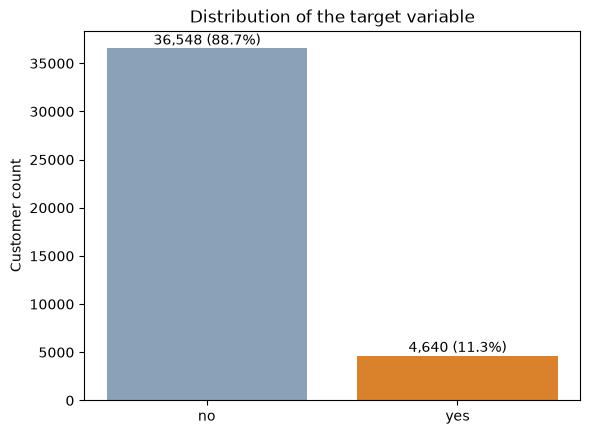

In [55]:
counts = df["y"].value_counts()
plt.bar(["no", "yes"], counts.values, color=["#8aa2b8", "#d9822b"])
for i, v in enumerate(counts.values):
    plt.text(i, v + 400, f"{v:,} ({v / len(df) * 100:.1f}%)", ha="center")
plt.ylabel("Customer count")
plt.title("Distribution of the target variable")
plt.show()

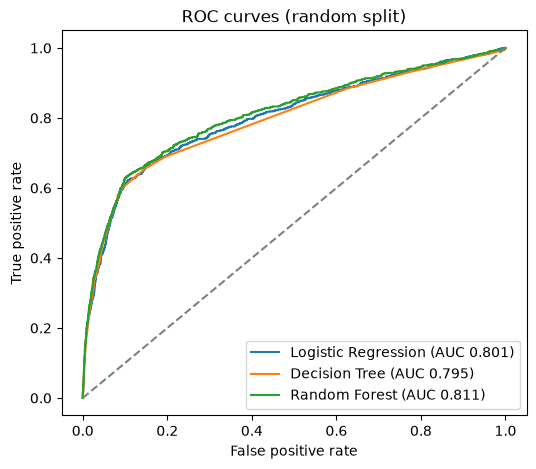

In [56]:
plt.figure(figsize=(6, 5))
for name, proba in [("Logistic Regression", y_proba),
                    ("Decision Tree", y_proba_t),
                    ("Random Forest", y_proba_rf)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, proba):.3f})")

plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves (random split)")
plt.legend(loc="lower right")
plt.show()

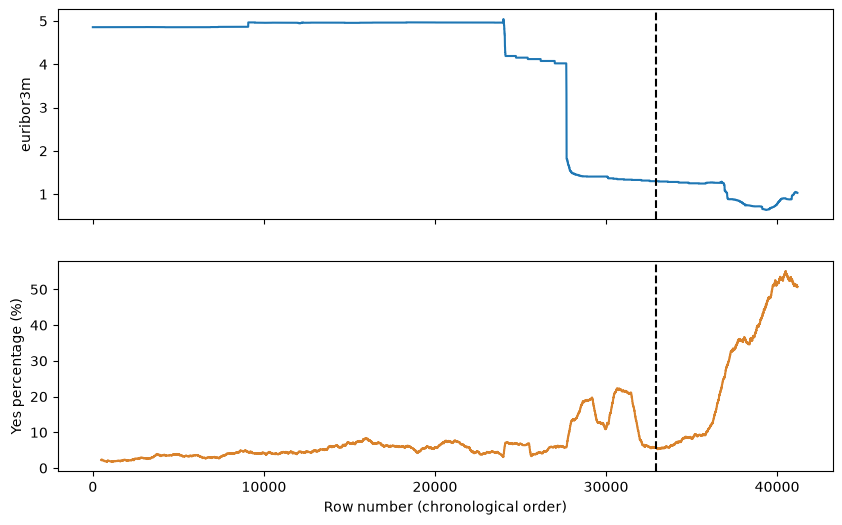

In [57]:
y_num = df["y"].map({"no": 0, "yes": 1})
roll = y_num.rolling(1500, min_periods=500).mean() * 100
cut = int(len(df) * 0.8)

fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axs[0].plot(df["euribor3m"].values)
axs[0].set_ylabel("euribor3m")
axs[1].plot(roll.values, color="#d9822b")
axs[1].set_ylabel("Yes percentage (%)")
for a in axs:
    a.axvline(cut, color="black", linestyle="--")
axs[1].set_xlabel("Row number (chronological order)")
plt.show()

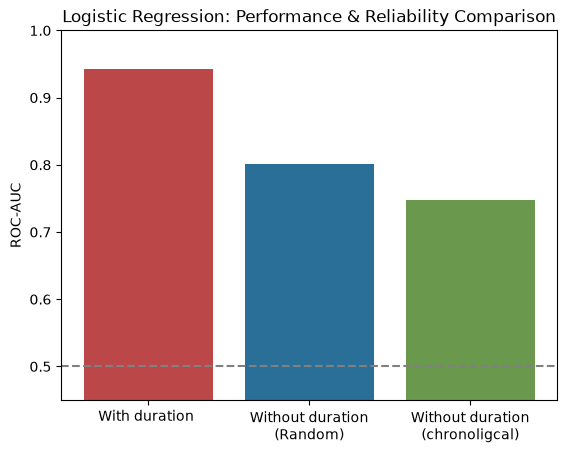

In [58]:
auc_dur = roc_auc_score(y_test_d, y_proba_d)
auc_rand = roc_auc_score(y_test, y_proba)
auc_time = roc_auc_score(y_test_t, y_proba_lt)

plt.bar(["With duration ", "Without duration\n(Random)", "Without duration\n(chronoligcal)"],
        [auc_dur, auc_rand, auc_time], color=["#bc4749", "#2a6f97", "#6a994e"])
plt.axhline(0.5, color="gray", linestyle="--")
plt.ylim(0.45, 1.0)
plt.ylabel("ROC-AUC")
plt.title("Logistic Regression: Performance & Reliability Comparison")
plt.show()